This notebook aims to implement Deep BSDE method for the heat equation in 1 dim and 10 dim.

In [364]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
torch.manual_seed(0)

T = 1.0
N = 20
dt = T / N
d = 1
xi = np.zeros(d) #starting point

In [365]:
def g(x):
    return (x**2).sum(-1)

def u_exact(t, x):
    d = x.shape[-1]
    return g(x) + d * (T - t)

def grad_u_exact(t, x):
    return 2 * x

def sample_paths(M):
    dW = rng.normal(0.0, np.sqrt(dt), size = (M, N, d))
    W = np.concatenate([np.zeros((M, 1, d)), np.cumsum(dW, axis=1)], axis=1)
    X = xi + W
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)

define y0 as the parameter, Adam as the optimizer of y0 w. learning rate 0.05

In [366]:
y0 = torch.nn.Parameter(torch.tensor(0.0))
opt = torch.optim.Adam([y0], lr=0.05)

Simple training loop with Z = 0 in pyTorch

In [367]:
n_iter = 1000
M = 256
loss_history = np.zeros(n_iter)
y0_history = np.zeros(n_iter)
for it in range(n_iter):
    X, dW = sample_paths(M)
    y = torch.ones(M)*y0 # vector of length M with y0 everywhere, tensor
    for step in range(N): # walk through each timestep
        Z = torch.zeros(M, d)
        y = y + (Z * dW[:,step,:]).sum(-1)
    #l2 loss: 
    X_t = X[:, -1, :]
    loss = torch.mean((y - g(X_t))**2)

    opt.zero_grad() #clear prev. gradient
    loss.backward() #compute new gradient
    opt.step() # update y0

    loss_history[it] = loss.item()
    y0_history[it] = y0.item()

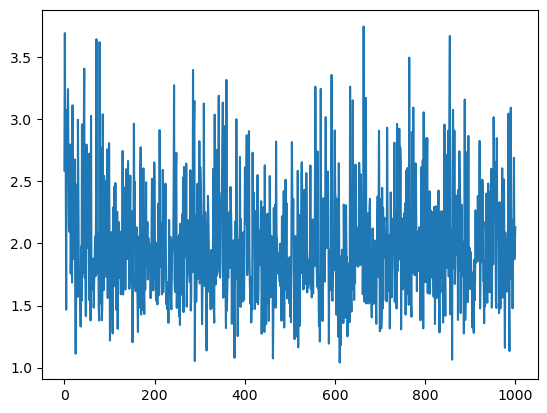

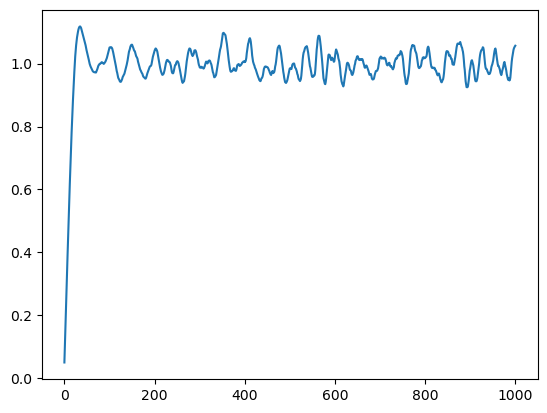

In [368]:
t = np.linspace(0, 1000, n_iter)
plt.plot(t, loss_history)
plt.show()
plt.plot(t, y0_history)
plt.show()

Learning Z

In [369]:
def subnet(d, width):
    return nn.Sequential(
            nn.Linear(in_features=d, out_features=width),
            nn.ReLU(),
            nn.Linear(width, width),
            nn.ReLU(),
            nn.Linear(width, d),
            )

In [370]:
class Model(nn.Module):
    def __init__(self, d, N, width):
        super().__init__()
        self.z0 = torch.nn.Parameter(torch.zeros(d))
        self.y0 = torch.nn.Parameter(torch.tensor(0.0))
        self.nets = nn.ModuleList([subnet(d, width) for _ in range(N-1)])

    def forward(self, X, dW):
        Y = torch.ones(len(X))*self.y0
        Z = self.z0
        Y = Y + (Z * dW[:,0,:]).sum(-1)
        for step in range(1, len(self.nets)+1):
            Z = self.nets[step-1](X[:, step, :])
            Y = Y + (Z * dW[:,step,:]).sum(-1)
        return Y

Training the model

In [371]:
n_iter = 1000
M = 256
loss_history = np.zeros(n_iter)
y0_history = np.zeros(n_iter)
model = Model(d, N, d + 10)


# two different learningrates for y0 and Z
opt = torch.optim.Adam([
    {"params": [model.y0], "lr": 1.0},
    {"params": [p for name, p in model.named_parameters() if name != "y0"], "lr": 1e-2},
])

for it in range(n_iter):
    X, dW = sample_paths(M)
    y = model.forward(X, dW)
    
    #l2 loss: 
    X_t = X[:, -1, :]
    loss = torch.mean((y - g(X_t))**2)

    opt.zero_grad() #clear prev. gradient
    loss.backward() #compute new gradient
    opt.step() # update y0, z0 and the weight

    loss_history[it] = loss.item()
    y0_history[it] = model.y0.item()
    

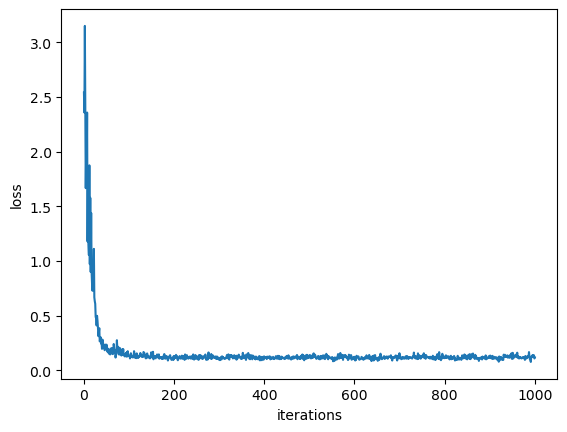

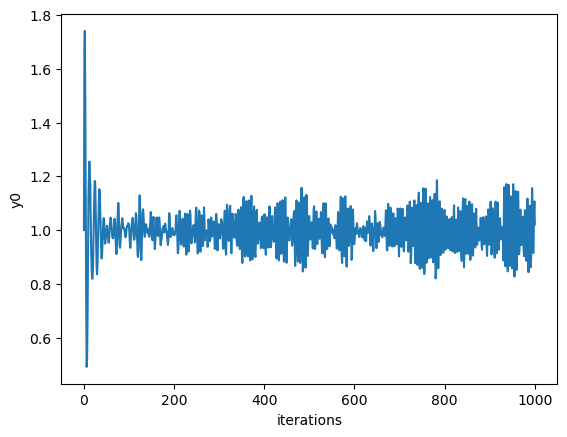

In [372]:
t = np.linspace(0, 1000, n_iter)
plt.plot(t, loss_history,)
plt.xlabel("iterations")
plt.ylabel("loss")
plt.show()
plt.plot(t, y0_history)
plt.xlabel("iterations")
plt.ylabel("y0")
plt.show()

In [373]:
X, dW = sample_paths(3000) # unseen paths
n = 16
X_n = X[:,n,:] #shape (M_test, d)
net = torch.no_grad(model.nets[n-1])
Z_learn = net(X_n)
Z_exact = grad_u_exact(dt*n, X_n)

Beyond solving for the initial value $y(0, \xi)$, the training produces $Z_n$, the NN approximating $\nabla u$, which uses the input $X_n$. For the 1d heat eq. we have an exact solution: $ \nabla u = 2x$

### When d = 1:
The plot below inspects the neural network $Z_{16}$ i.e at $t = 16*1/20 = 0.8 s$. Each dot is 1 of 3000 simulated BM paths: the x-value is the position at $t = 0.8s$, i.e $X_{16}$ and its y-value is the output from the network $Z_{16}$. The values from the net are compared with the exact value of $\nabla u = 2x$. The network is generally approximating most accurate at x = 0. Logical since most paths lie around that value, outliers does not affect the loss function as much.


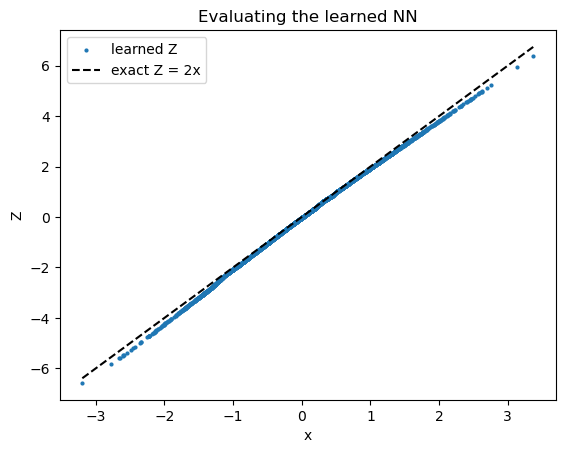

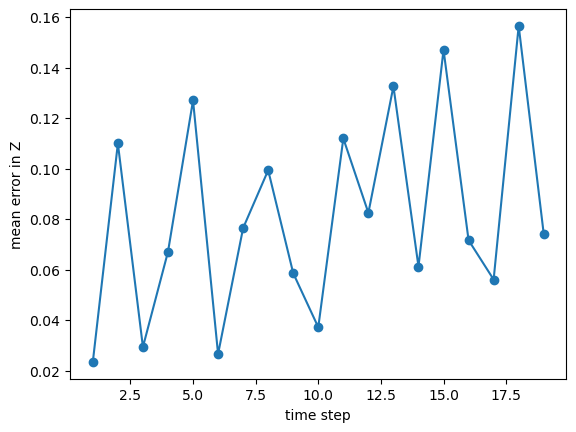

In [374]:
x = X_n.numpy()[:, 0]
z_learn = Z_learn.numpy()[:, 0]

x_sorted = np.sort(x)
plt.scatter(x, z_learn, s=4, label="learned Z")
plt.plot(x_sorted, 2 * x_sorted, "k--", label="exact Z = 2x")
plt.xlabel("x")
plt.title("Evaluating the learned NN")
plt.ylabel("Z")
plt.legend()
plt.show()

errors = []
with torch.no_grad():
    for k in range(1, N):
        Zk = model.nets[k - 1](X[:, k, :])
        errors.append((Zk - grad_u_exact(k * dt, X[:, k, :])).abs().mean().item())

plt.plot(range(1, N), errors, "o-")
plt.xlabel("time step")
plt.ylabel("mean error in Z")
plt.show()
